In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\yoanl\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [2]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python

%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
df = pd.read_csv(r"C:\Users\yoanl\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3\amz_uk_price_prediction_dataset.csv")

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
num = df.select_dtypes(include="number")
cat = df.select_dtypes(exclude="number")

In [6]:
df.isna().sum()
missing = df.isna().sum()
missing = missing[missing > 0]
missing

Series([], dtype: int64)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
spaced_values=df.eq(" ").sum()
spaced_values

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

******

PART 1

In [17]:
cat.category.value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [87]:
crosstab_result = pd.crosstab(cat.category,cat.isBestSeller)
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [37]:
crosstab_proportion = pd.crosstab(cat.category,cat.isBestSeller, normalize="index")
crosstab_proportion


isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [90]:
crosstab_result["False (%)"] = (crosstab_proportion[False] * 100).round(2)
crosstab_result["True (%)"] = (crosstab_proportion[True] * 100).round(2)

crosstab_result

isBestSeller,False,True,False (%),True (%)
category,,,,
3D Printers,247,1,99.60,0.40
3D Printing & Scanning,4065,2,99.95,0.05
Abrasive & Finishing Products,245,5,98.00,2.00
Action Cameras,1696,1,99.94,0.06
Adapters,251,3,98.82,1.18
...,...,...,...,...
Wind Instruments,243,7,97.20,2.80
Window Treatments,234,5,97.91,2.09
Women,17559,213,98.80,1.20


In [80]:
print(crosstab_result.columns)

Index([False, True, 'False (%)', 'True (%)'], dtype='object', name='isBestSeller')


In [91]:
crosstab_sorted = crosstab_result.sort_values(by="True (%)", ascending=False)
crosstab_sorted.head(15)


isBestSeller,False,True,False (%),True (%)
category,,,,
Grocery,9008,556,94.19,5.81
Smart Home Security & Lighting,98,6,94.23,5.77
Health & Personal Care,9017,552,94.23,5.77
Mobile Phone Accessories,248,11,95.75,4.25
Power & Hand Tools,8353,306,96.47,3.53
"Billiard, Snooker & Pool",241,8,96.79,3.21
Pet Supplies,9152,285,96.98,3.02
Home Brewing & Wine Making,239,7,97.15,2.85
Wind Instruments,243,7,97.20,2.80


In categories such as grocery, smart home security and lighting, and health and personal care, best sellers are more common with more than 5.7%.

In [52]:
from scipy.stats import chi2_contingency



In [60]:
_, chi2_pvalue, _, _= chi2_contingency(crosstab_result)
float(chi2_pvalue) < 0.05

True

In [61]:
float(chi2_pvalue)

0.0

p_value < 0.05. there is a significant association between category and isBestSeller variables.

In [62]:
from scipy.stats.contingency import association

In [68]:
association(crosstab_result, method='cramer')

0.1222829439760564

cramer test = 0.12. weak association


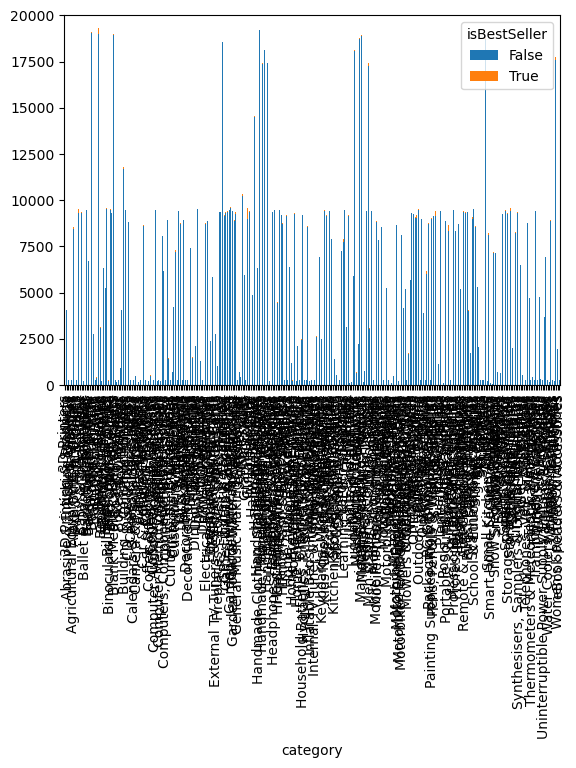

In [88]:
crosstab_result.plot(kind='bar', stacked=True)
plt.ylim(0,20000)
plt.show()

****************

PART 2

In [92]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [104]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

outliers = outlier_slayer(df.price)
list(outliers)

condition = ~df["price"].isin(list(outliers)) 
df_no_outliers = df[condition]

In [107]:
sum(df_no_outliers.price.isin(list(outliers)))

0

In [112]:
top20 = df_no_outliers.category.value_counts().head(20)

In [115]:
list(top20.index)

['Sports & Outdoors',
 'Beauty',
 'Bath & Body',
 'Manicure & Pedicure Products',
 'Handmade Clothing, Shoes & Accessories',
 'Make-up',
 'Skin Care',
 'Hair Care',
 'Birthday Gifts',
 'Handmade Gifts',
 'Handmade Home Décor',
 'Luggage and travel gear',
 'Women',
 'Fragrances',
 'Handmade Kitchen & Dining',
 'Handmade Artwork',
 'Handmade Home & Kitchen Products',
 'Handmade Jewellery',
 'Men',
 'Baby']

In [122]:
condition = df_no_outliers["category"].isin(list(top20.index)) 
df_no_outliers_top20 = df_no_outliers[condition]
df_no_outliers_top20.category.value_counts()

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: count

C:\Users\yoanl\AppData\Local\Temp\ipykernel_13256\1284987889.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_no_outliers_top20, x="category", y="price", palette="coolwarm")


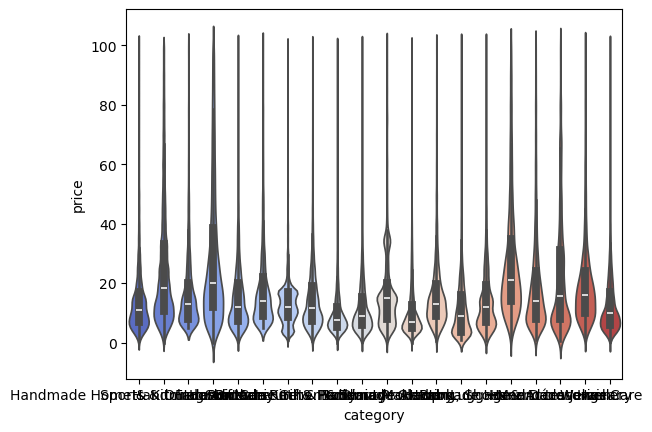

In [123]:
sns.violinplot(data=df_no_outliers_top20, x="category", y="price", palette="coolwarm")
plt.show()

In [136]:
medianprice_df = df_no_outliers[["category","price"]].groupby("category").median()
medianprice_df.sort_values(by="price", ascending=False).head(20)

,price
category,
Desktop PCs,74.000
Boxing Shoes,69.790
Tablets,69.000
Graphics Cards,68.540
Motherboards,67.920
Made in Italy Handmade,64.000
Digital Frames,63.900
Streaming Clients,62.680
Golf Shoes,62.390


electronic devices tends to have the highest median price. (Desktop PCs,Tablets, Graphics Cards, Motherboards...)

In [137]:
top10 = df_no_outliers.category.value_counts().head(10)
list(top10.index)
condition = df_no_outliers["category"].isin(list(top10.index)) 
df_no_outliers_top10 = df_no_outliers[condition]
df_no_outliers_top10.category.value_counts()

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Name: count, dtype: int64

C:\Users\yoanl\AppData\Local\Temp\ipykernel_13256\1165397682.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_no_outliers_top10, x="category", y="price", palette="coolwarm", errorbar=None)


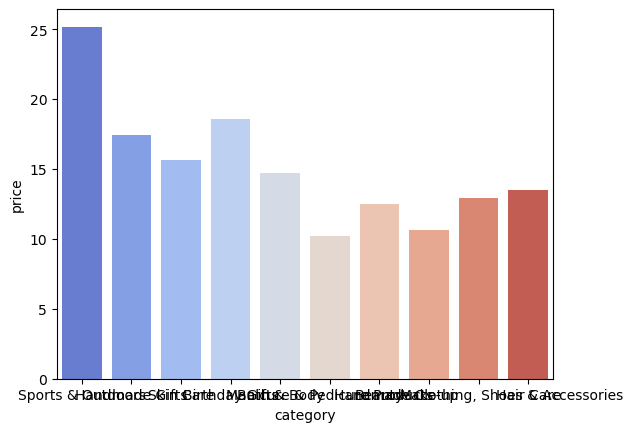

In [141]:
sns.barplot(data=df_no_outliers_top10, x="category", y="price", palette="coolwarm", errorbar=None)
plt.show()

In [145]:
meanprice_df = df_no_outliers[["category","price"]].groupby("category").mean()
meanprice_df.sort_values(by="price", ascending=False).head(10)

,price
category,
Motherboards,68.772432
Boxing Shoes,67.417803
Desktop PCs,66.915562
Tablets,66.552971
Graphics Cards,65.103509
Digital Frames,60.745129
Streaming Clients,60.241803
Hockey Shoes,60.094796
Computer Cases,58.339884


still same categories, electronic devices and sports shoes

C:\Users\yoanl\AppData\Local\Temp\ipykernel_13256\2664558124.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_no_outliers_top10, x="category", y="stars", palette="coolwarm", legend=True)


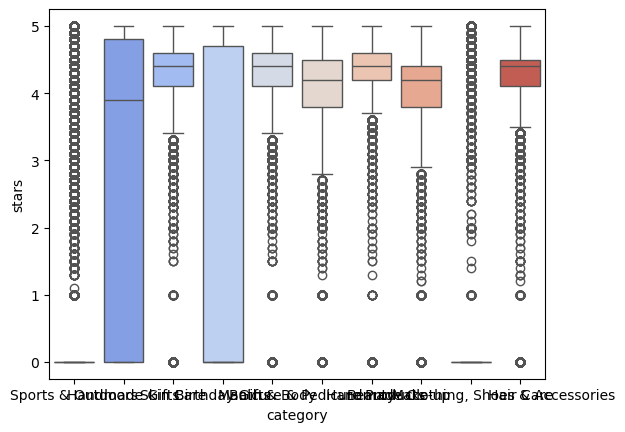

In [146]:
sns.boxplot(data=df_no_outliers_top10, x="category", y="stars", palette="coolwarm", legend=True)
plt.show()

In [147]:
medianrating_df = df_no_outliers[["category","stars"]].groupby("category").median()
medianrating_df.sort_values(by="stars", ascending=False).head(10)

,stars
category,
Computer Memory,4.7
Building & Construction Toys,4.6
Office Paper Products,4.6
Luxury Food & Drink,4.6
Kids' Play Figures,4.6
Hobbies,4.6
"Beer, Wine & Spirits",4.6
Laptop Accessories,4.6
Cables & Accessories,4.5


Computer Memory	4.7
Building & Construction Toys	4.6
Office Paper Products	4.6
Luxury Food & Drink	4.6

***********************

PART 3

In [148]:
df_no_outliers[["stars","price"]].corr()

,stars,price
stars,1.000000,-0.077673
price,-0.077673,1.000000


-0.0777: insignificant negative correlation. these two variables are not dependent of each other

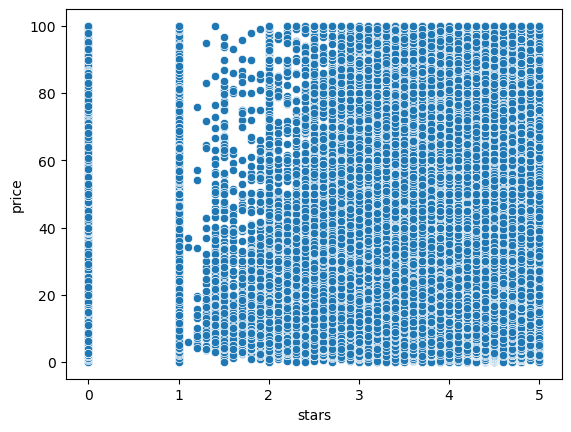

In [149]:
sns.scatterplot(data=df_no_outliers, x='stars', y='price')
plt.show()

there is no patterns. only thing we can say, from 0 to 1 no ratings.

In [150]:
num = df_no_outliers.select_dtypes(include="number")
correlation_matrix = num.corr()

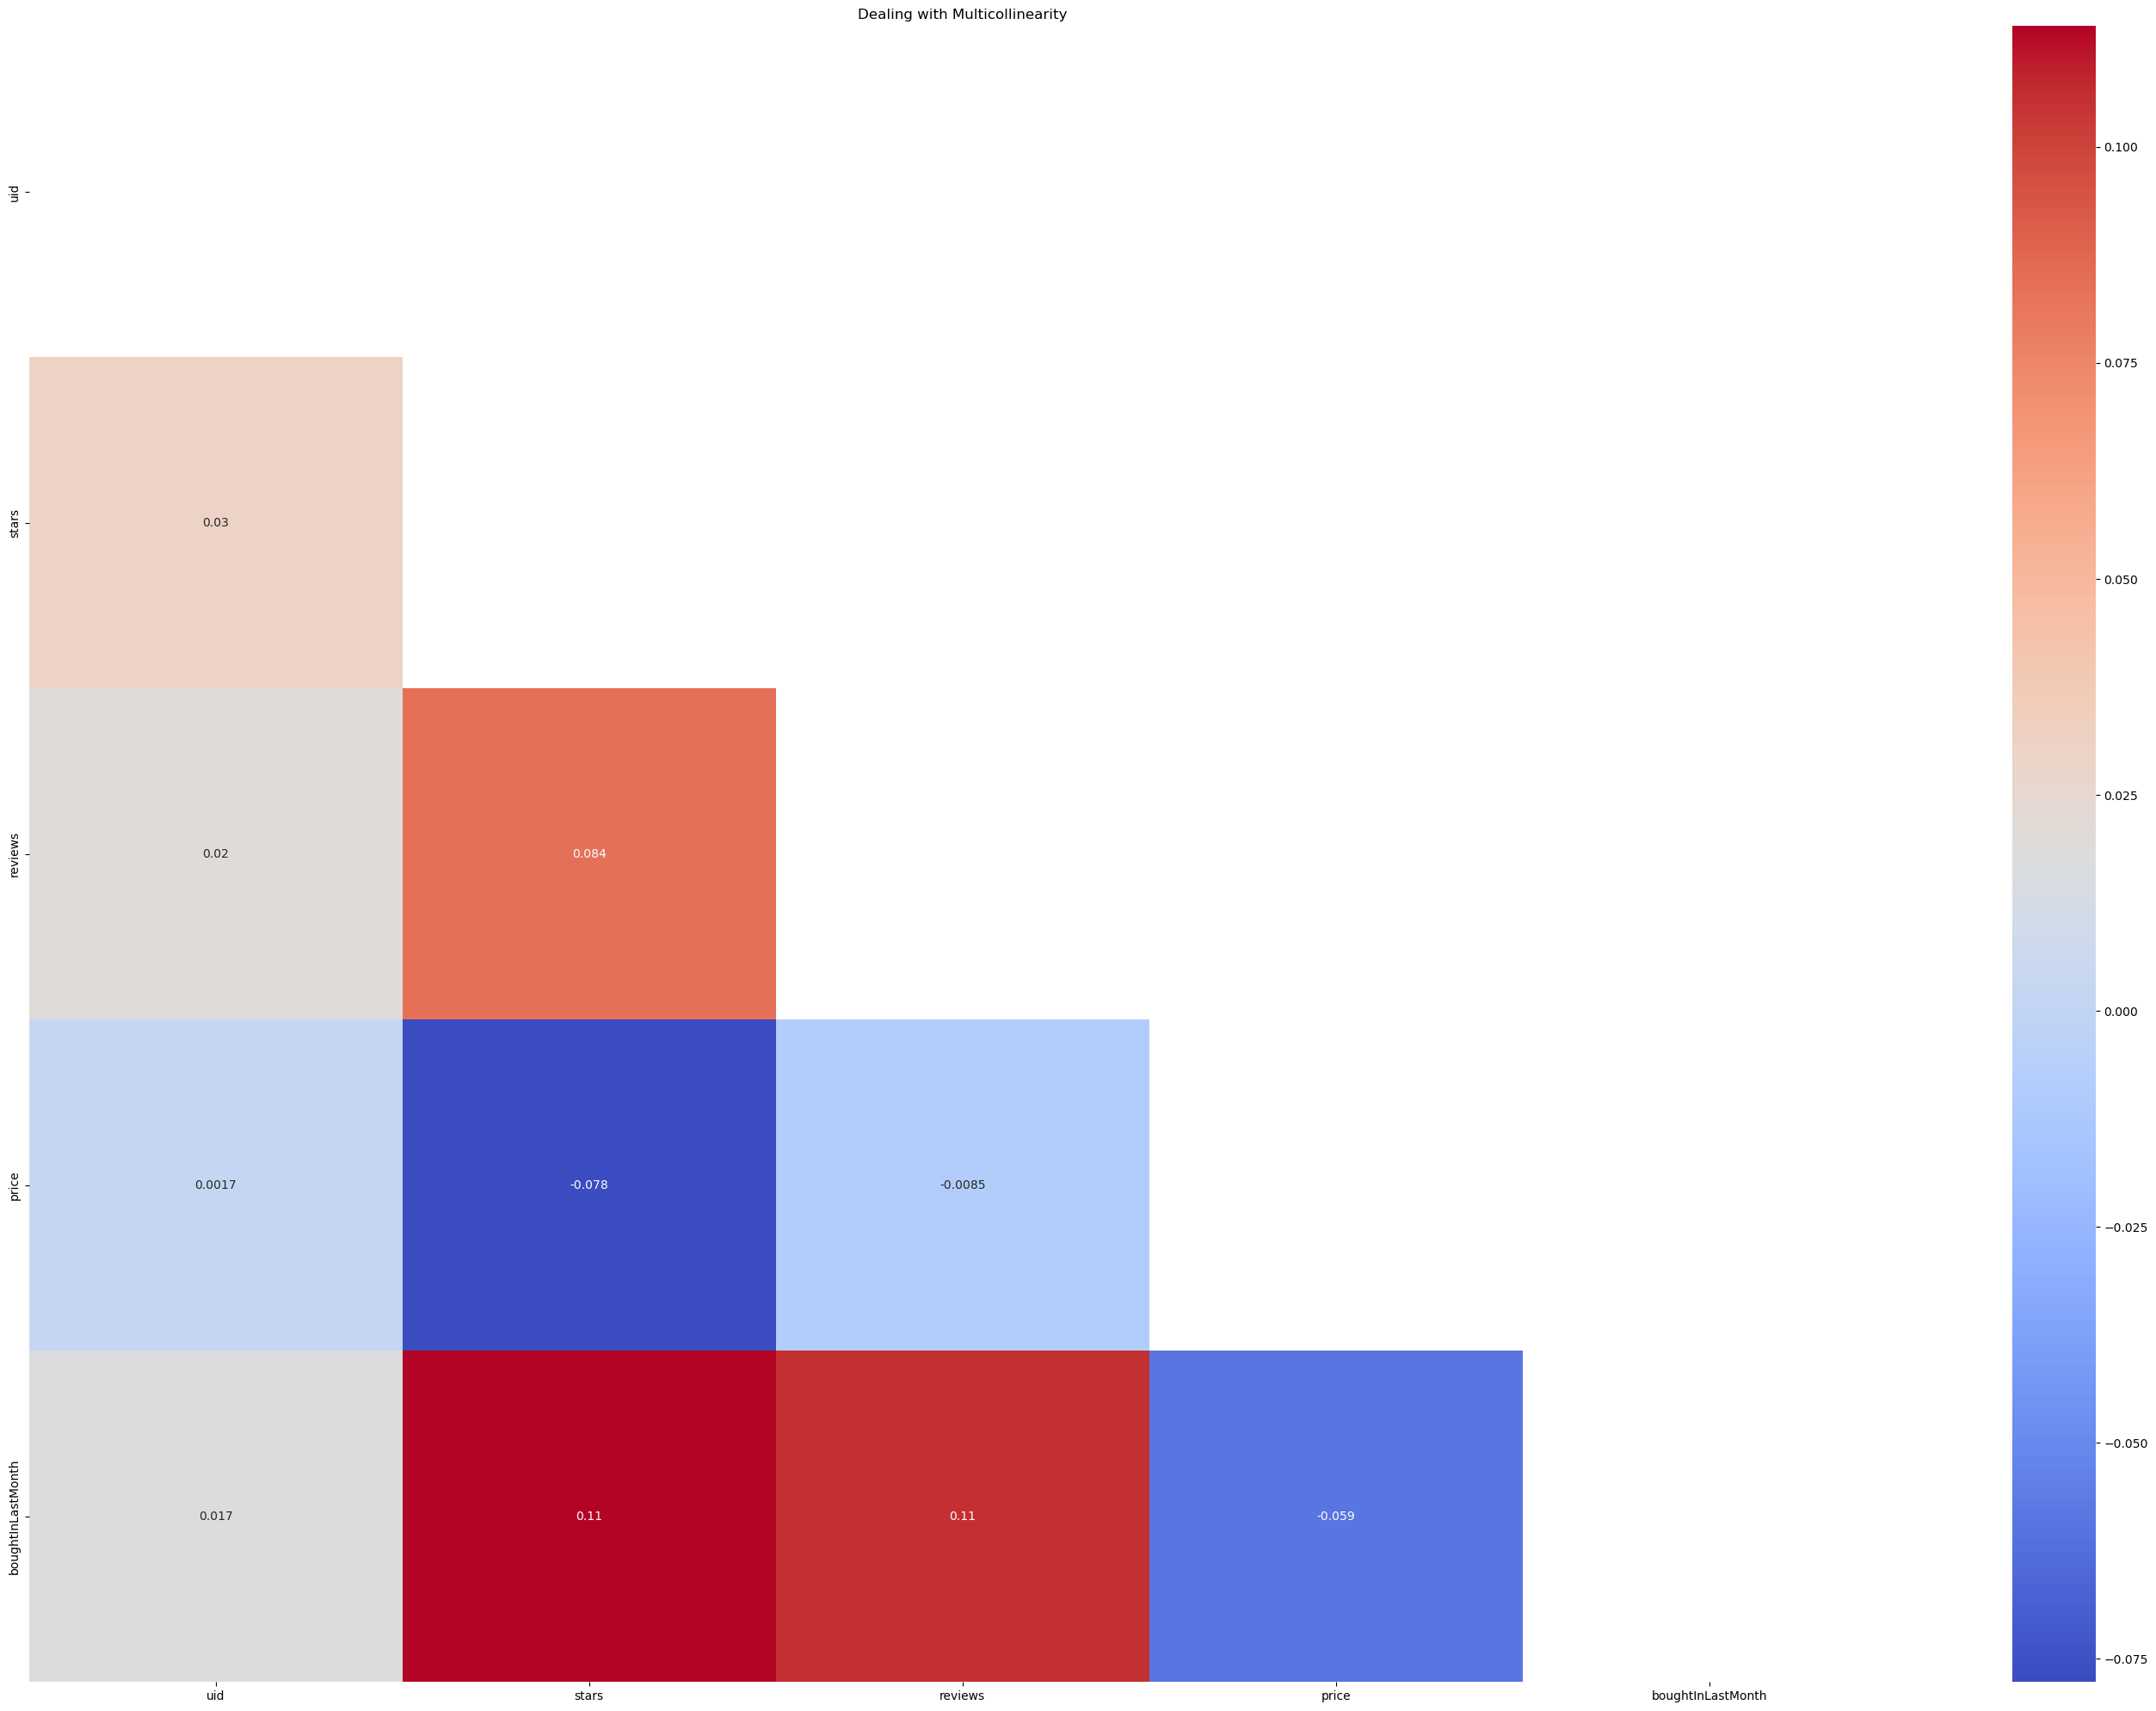

In [151]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Dealing with Multicollinearity")
plt.show()

not really correlation between numeric variables


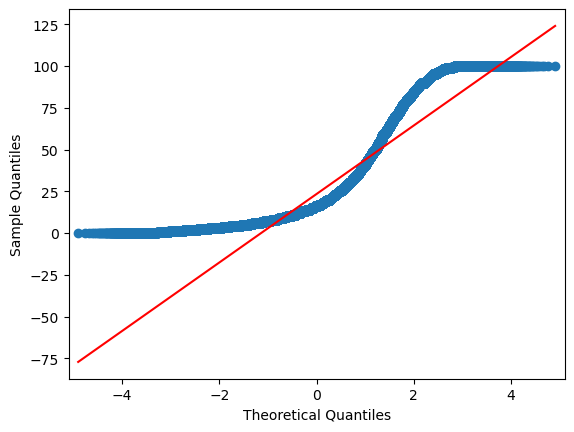

In [152]:
import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df_no_outliers['price'], line='s');
plt.show()

price is not normally distributed. heavy tails.